Multi-dimensional chemical profiling demands high-precision decision boundaries. To accurately classify environmental samples where raw readings span completely different scales, you must isolate the optimal hyperplane configuration. In this project, you build and fine-tune a `Support Vector Classifier` (SVC) on a complex chemical signature benchmark. You will standardize non-linear feature matrices, engineer a rigid custom binary log-loss metric to penalize overconfident algorithmic errors, and execute cross-validated hyperparameter sweeps via `GridSearchCV`. This creates the precise mathematical tuning and explicit engineering handoff needed to map delicate soil profiles before deploying crop suitability models in the field.


This module, we will classify the quality of a local fermented grain brew from chemical assay data — a dataset with the same structure as soil chemistry classification. The ministry's agricultural cooperative already runs lab assays on batches of sorghum- and millet-based brew sold in regional markets, and the resulting **Brew Quality Bank** gives us a real, lower-stakes chemistry classification problem to prove ourselves on before the soil data arrives. The variables (acidity, sulphates, pH, alcohol content) are direct proxies for the kind of chemical readings we will encounter when classifying field suitability in Module 3.

## **The Dataset**

We are using the **Maji Ndogo Brew Quality Bank** — chemical assay results for batches of a fermented grain brew produced from two staple crops grown across Maji Ndogo's provinces. Each batch was scored by the cooperative's tasting panel and analysed in the lab, described by the following variables:

| Feature | Description |
|---|---|
| `fixed acidity` | Tartaric-acid-equivalent concentration |
| `volatile acidity` | Acetic acid concentration |
| `citric acid` | Citric acid (adds freshness) |
| `residual sugar` | Remaining sugar after fermentation |
| `chlorides` | Salt concentration |
| `free sulfur dioxide` | Free form of SO₂ |
| `total sulfur dioxide` | Total SO₂ (free + bound) |
| `density` | Density relative to water |
| `pH` | Acidity/alkalinity |
| `sulphates` | Antimicrobial and antioxidant additive |
| `alcohol` | Alcohol percentage |
| `type` | Grain base — 0 = sorghum, 1 = millet |
| `quality` | Panel score between 0 and 10 (our **target**) |

In [14]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

In [2]:
def style_plot(
    ax,
    title=None,
    xlabel=None,
    ylabel=None,
    figsize=(9, 5),
    grid=True,
    remove_spine=True,
    title_fontsize=14,
    label_fontsize=12,
):
    if title:
        ax.set_title(
            title,
            fontsize=title_fontsize,
            fontweight="bold"
        )

    if xlabel:
        ax.set_xlabel(
            xlabel,
            fontsize=label_fontsize
        )

    if ylabel:
        ax.set_ylabel(
            ylabel,
            fontsize=label_fontsize
        )

    if grid:
        ax.grid(
            True,
            linestyle="--",
            linewidth=0.7,
            alpha=0.3,
            color="0.75"
        )

    if remove_spine:
        for spine in ax.spines.values():
            spine.set_visible(False)

        ax.tick_params(length = 0)

    return ax

In [3]:
path = '../data/brew_quality.csv'
df = pd.read_csv(path)
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,type,quality
0,6.968017,0.153255,0.261715,6.947768,0.101138,13.026618,61.812829,0.993395,3.132665,0.515255,12.670487,0,7
1,7.912219,0.224353,0.600326,3.721025,0.019887,13.511783,79.139056,0.994823,3.233324,0.589113,9.208736,0,6
2,5.660172,0.295264,0.662057,2.271575,0.010000,7.165821,11.057284,1.000590,3.074976,0.272768,11.113903,1,7
3,5.279642,0.297056,0.335699,3.661823,0.074799,7.989486,40.316911,0.990190,2.978561,0.652717,10.020545,0,6
4,6.971226,0.378522,0.131887,5.153600,0.065483,7.572312,97.796655,0.992720,3.202713,0.581615,11.603894,0,6


In [8]:
# check the data types
for col in df.columns:
    print(f"{col:>20}: {df[col].dtypes}")

       fixed acidity: float64
    volatile acidity: float64
         citric acid: float64
      residual sugar: float64
           chlorides: float64
 free sulfur dioxide: float64
total sulfur dioxide: float64
             density: float64
                  pH: float64
           sulphates: float64
             alcohol: float64
                type: int64
             quality: int64


In [10]:
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 6497
Number of columns: 13


In [11]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.214559,1.300768,3.800000,6.353572,7.204307,8.097935,11.766593
volatile acidity,6497.0,0.360003,0.247142,0.080000,0.173744,0.301614,0.481286,1.600000
citric acid,6497.0,0.394855,0.198136,0.002264,0.238571,0.379995,0.533523,0.977245
residual sugar,6497.0,3.714719,2.992056,0.600000,1.517675,2.921095,5.004273,27.736622
chlorides,6497.0,0.040363,0.027757,0.010000,0.019322,0.033691,0.053916,0.219954
free sulfur dioxide,6497.0,14.958266,9.516028,1.000000,7.945367,12.969642,19.929274,83.298442
total sulfur dioxide,6497.0,75.252543,35.990754,5.295182,49.066767,69.700204,94.094135,323.142014
density,6497.0,0.994525,0.002995,0.987000,0.992442,0.994526,0.996672,1.004000
pH,6497.0,3.219592,0.160620,2.700000,3.112395,3.222071,3.330443,3.818607
sulphates,6497.0,0.547758,0.305571,0.200000,0.309907,0.486089,0.704087,2.000000


## **Challenge 1: Data Preprocessing**

Sanaa has been specific about how she wants the quality labels handled. Brew quality scores in this dataset range from 3 to 9, and while that gives us nine possible classes, most of the real-world decisions reduce to a binary question: is this batch acceptable or not? We apply the same framing to Maji Ndogo field data — is this field suitable for irrigation or not. The binary framing keeps the model interpretable and the business decision clear.

Before the classifier sees any data, we also need to standardise the features. The chemical variables in this dataset have wildly different scales — sulphates are measured in grams per litre while total sulphur dioxide can reach hundreds of parts per million. Without standardisation, the SVC will weight high-magnitude features disproportionately and produce a badly calibrated decision boundary.

### **Task**

Write a function `data_preprocess` that:
- Takes a DataFrame as input.
- Converts `quality` labels:
    - Quality **≤ 4** → label **0** (lower quality)
    - Quality **≥ 5** → label **1** (higher quality)
- Fills any `NaN` values with zeros.
- Standardises the features using `sklearn`'s `StandardScaler`.
- Splits the data into **75% training** and **25% testing**, with `random_state=42`.
- Returns two tuples: `(X_train, y_train), (X_test, y_test)`.

In [33]:
def data_preprocess(df):
    # Create binary target
    y = (df["quality"] >= 5).astype(int)

    # Select features
    X = df.drop(columns=["quality"])

    # Fill missing values
    X = X.fillna(0)

    # Standardise features
    scaler = StandardScaler()
    X = scaler.fit_transform(X)

    # Split into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.25,
        random_state=42
    )

    return (X_train, y_train), (X_test, y_test)


In [34]:
(X_train, y_train), (X_test, y_test) = data_preprocess(df)

print(X_train[:2])
print(y_train[:2])
print(X_test[:2])
print(y_test[:2])

[[ 0.0788577  -0.32538893 -0.17534887 -0.11007128  0.06674735  0.46531515
   1.17818679  2.41030969 -0.70042723  0.84125854 -1.30154194  1.71602681]
 [-1.92454798  1.6299215   1.35374038 -0.57515249 -0.28964441  0.10320922
  -0.70610967 -1.31711707 -0.12747816  0.1400211  -0.95732519  1.71602681]]
1539    1
1109    1
Name: quality, dtype: int64
[[-0.13924929  0.35413355 -1.29463181  1.28553674 -0.51813495 -0.09170206
   1.07569514  0.23211965 -1.40767708 -0.81429035  0.12353384 -0.58274148]
 [ 0.51546331 -1.1330513   0.35623528 -0.42741846  0.00794936  0.28186024
  -1.44797776  0.64443535 -0.96897622  2.73442186 -1.46931266 -0.58274148]]
3103    0
1419    1
Name: quality, dtype: int64


In [35]:
print(X_train.shape)

(4872, 12)


 ## **Challenge 2: Training a Baseline Model**

Before we run any optimisation, we need a reference point. Sanaa will only trust an improved model if she can see what it improved from. A baseline SVC with default parameters gives us that anchor — we measure its log-loss and accuracy, then compare those numbers against the tuned version in Challenges 5 and 6.

The Support Vector Classifier finds a hyperplane in the feature space that maximally separates the two classes. The `gamma` parameter controls how far the influence of a single training sample reaches. Setting it to `'auto'` scales gamma inversely with the number of features, which is a sensible default when we do not yet know the right scale.

### **Task**

Write a function `train_SVC_model` that:
- Takes two numpy arrays `X_train` and `y_train` as input.
- Returns a fitted `SVC` model with:
    - `random_state = 40`
    - `gamma = 'auto'`

In [17]:
def train_SVC_model(X_train, y_train):
    # Create the baseline SVC model
    svc = SVC(
        random_state=40,
        gamma="auto"
    )

    # Fit the model
    svc.fit(X_train, y_train)

    return svc

In [19]:
svc = train_SVC_model(X_train, y_train)

print(svc.predict(X_test))
print(svc.classes_)

[1 1 1 ... 1 1 1]
[0 1]


## **Challenge 3: Custom Scoring Function**

Accuracy is a useful headline metric, but Sanaa needs a more sensitive measure of model quality. She has seen classifiers that look good on accuracy but systematically fail on the minority class — and in the context of crop recommendations, a confident wrong prediction can mean an entire growing season is wasted on an unsuitable crop.

We implement **log-loss** — a metric that penalises confident wrong predictions more severely than uncertain ones. A prediction of 0.99 for the wrong class incurs a much larger penalty than a prediction of 0.51. This asymmetry makes log-loss the right metric when the cost of being confidently wrong is high. This is the same metric Sanaa will use to evaluate crop classifiers in Module 3.

The formula is:

$$H(p,q) = -\frac{1}{N} \sum_{i=1}^{N} \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]$$

### **Task**

Write a function `custom_scoring_function` that:
- Takes two numpy arrays: `y_true` and `y_pred`.
- Clips predictions using `epsilon = 1e-15` to avoid log(0).
- Returns a **float64** for the log-loss value, rounded to **7 decimal places**.

> **Hint:** `np.maximum` and `np.minimum` are useful for clipping values.

### **Expected Output**
```
Log Loss value:  1.020245
Accuracy:  0.9705
```

In [21]:
def custom_scoring_function(y_true, y_pred):

    epsilon = 1e-15

    y_pred = np.maximum(epsilon, y_pred)
    y_pred = np.minimum(1 - epsilon, y_pred)

    log_loss = -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

    return np.float64(round(log_loss, 7))

In [22]:
y_pred = svc.predict(X_test)
print('Log Loss value: ', custom_scoring_function(y_test, y_pred))
print('Accuracy: ', round(accuracy_score(y_test, y_pred), 4))

Log Loss value:  1.020245
Accuracy:  0.9705


## __Hyperparameter Optimisation__

A 96.37% accuracy baseline is already impressive, but log-loss of 1.25 suggests our model is making some confident mistakes. Let's use GridSearchCV to find better hyperparameters.

## __Challenge 4: Getting Model Hyperparameters__

Before Sanaa will authorise a grid search, she wants to see exactly which levers we are pulling. Every sklearn estimator exposes its configurable parameters through `get_params()`. We will use this to inspect the full list of SVC hyperparameters — knowing what is tuneable before we decide what to tune is good engineering discipline.

This function also serves as a reusable diagnostic tool. In Module 3, when we compare multiple classifier types on the Maji Ndogo data, we can call this same function on any sklearn model to inspect its parameter space before designing the search grid.

### __Task__

Write a function `get_model_hyperparams` that:
- Takes an sklearn model (estimator) object as input.
- Returns a **list** of parameter names for the given model.


In [23]:
def get_model_hyperparams(model):
    return list(model.get_params().keys())

In [25]:
svc = SVC()

hyperparams = get_model_hyperparams(svc)
for params in hyperparams:
    print(params)

C
break_ties
cache_size
class_weight
coef0
decision_function_shape
degree
gamma
kernel
max_iter
probability
random_state
shrinking
tol
verbose


## __Challenge 5: Hyperparameter Search__

Now we run the search. Sanaa has approved a focused grid over two hyperparameters — `C` (the regularisation strength) and `gamma` (the kernel width). These two parameters control the fundamental bias-variance trade-off of the SVC: `C` controls how much we penalise misclassification, and `gamma` controls how tightly the decision boundary wraps around the training data.

We use our `custom_scoring_function` from Challenge 3 as the scoring metric, wrapped in sklearn's `make_scorer`. Because log-loss is a metric we want to **minimise**, we pass `greater_is_better=False`. GridSearchCV then selects the parameter combination that minimises log-loss across 5 cross-validation folds.

### __Task__

Write a function `tune_SVC_model` that:
- Takes `X_train` and `y_train` as input.
- Defines a parameter grid: `D = {'C': [0.1, 1, 10], 'gamma': [0.01, 0.1, 1]}`.
- Uses `custom_scoring_function` wrapped in `make_scorer` with `greater_is_better=False`.
- Returns a **fitted** `GridSearchCV` object with **5-fold cross-validation**.

> **Hint:** Look at `sklearn.metrics.make_scorer`.

   

In [ ]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import make_scorer

def tune_SVC_model(X_train, y_train):
    D = {
        "estimator__C": [0.1, 1, 10],
        "estimator__gamma": [0.01, 0.1, 1]
    }

    log_loss_scorer = make_scorer(
        custom_scoring_function,
        response_method="predict_proba",
        greater_is_better=False
    )

    model = CalibratedClassifierCV(
        SVC(),
        ensemble=False
    )

    grid_SVM = GridSearchCV(
        model,
        D,
        scoring=log_loss_scorer,
        cv=5
    )
    grid_SVM.fit(X_train, y_train)

    return grid_SVM

In [29]:
svc_tuned = tune_SVC_model(X_train, y_train)
y_pred_tuned = svc_tuned.predict(X_test)
print('Log Loss value: ', custom_scoring_function(y_test, y_pred_tuned))
print('Accuracy: ', round(accuracy_score(y_test, y_pred_tuned), 4))

Log Loss value:  0.9139679
Accuracy:  0.9735


## **Challenge 6: Extracting the Best Parameters**

The grid search is complete. Sanaa now needs the optimal hyperparameter values in a clean dictionary she can document and hand to the engineering team. When the ministry deploys the classifier to production, the infrastructure team will need these exact parameter values to instantiate the model correctly — not a `GridSearchCV` object, just the parameters.

This function extracts that dictionary from the fitted search object. It is a simple wrapper, but it is an important one: it makes the handoff from data science to engineering clean and explicit.

### **Task**

Write a function `get_best_params` that:
- Takes a fitted `GridSearchCV` object as input.
- Returns a **dictionary** of the optimal parameters.

In [32]:
def get_best_params(model):
    return model.best_params_

In [31]:
best_params = get_best_params(svc_tuned)
print(best_params)

{'estimator__C': 10, 'estimator__gamma': 0.01}


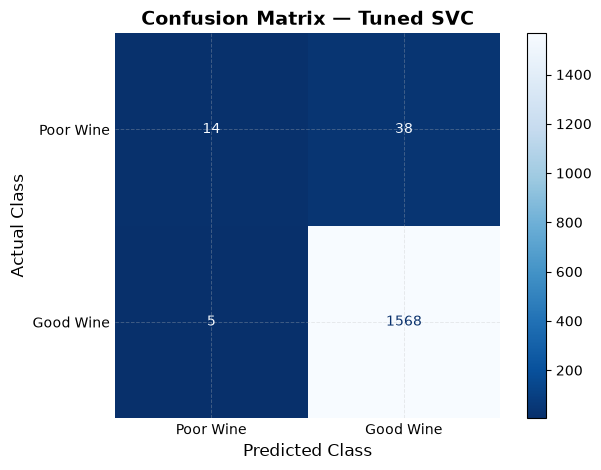

In [43]:
from sklearn.metrics import ConfusionMatrixDisplay
# Make predictions
y_pred_tuned = svc_tuned.predict(X_test)

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_tuned)

# Plot
fig, ax = plt.subplots()

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Poor Wine", "Good Wine"]
).plot(
    ax=ax,
    cmap="Blues_r",
    values_format="d",
)

style_plot(
    ax,
    title="Confusion Matrix — Tuned SVC",
    xlabel="Predicted Class",
    ylabel="Actual Class"
)

fig.tight_layout()
plt.show()